[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/makaroveo/itmo-python-data-analysis/blob/main/lab01/lab01_hierarchical.ipynb)

# Лабораторная работа 1. Иерархический кластерный анализ

Вариант 2: Economics of Cities. Макаров Семён, ИСУ 335173.

Задача: разбить города на группы иерархическим методом, обосновать число кластеров и объяснить, чем группы отличаются друг от друга.

## 1. Данные

В наборе 48 городов мира с показателями за 1991 год (данные Union Bank of Switzerland):

* Work: взвешенное среднее числа рабочих часов по 12 профессиям (судя по величине, часов в год);
* Price: индекс цен 112 товаров и услуг, включая аренду жилья, Цюрих = 100;
* Salary: индекс часовой зарплаты после налогов по 12 профессиям, Цюрих = 100.

Название города служит идентификатором и в кластеризации не участвует.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

FEATURES = ['Work', 'Price', 'Salary']
# цвета кластеров 1 и 2 на всех графиках
COLORS = {1: '#1f77b4', 2: '#ff7f0e'}
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})

In [2]:
def find_csv(name='Econom_Cities_data.csv'):
    # локально файл лежит рядом с ноутбуком
    if Path(name).exists():
        return Path(name)
    if 'google.colab' not in sys.modules:
        raise FileNotFoundError(f'Не нашёл {name}: положите его рядом с ноутбуком')
    # в Colab файла нет, поэтому открываю диалог загрузки
    from google.colab import files
    return Path(next(iter(files.upload())))


raw = pd.read_csv(find_csv(), sep=';', decimal=',', index_col='City')  # разделитель ';', десятичная запятая
print('Городов:', len(raw), '| столбцы:', raw.columns.tolist())
raw.describe().T

Городов: 48 | столбцы: ['Work', 'Price', 'Salary']


,count,mean,std,min,25%,50%,75%,max
Work,48.0,1384.958333,2404.897007,-9999.0,1740.75,1834.5,1972.75,2375.0
Price,48.0,68.860417,21.784659,30.3,49.65,70.5,81.70,115.5
Salary,48.0,-378.727083,2027.338052,-9999.0,12.25,40.3,58.70,100.0


## 2. Пропуски и первый взгляд на данные

В описательной статистике минимум Work и Salary равен −9999. Ни часов работы, ни индекса зарплаты с таким значением не бывает, значит, это код пропуска. Он уже испортил статистику: среднее Work получилось 1 385, а среднее Salary вообще отрицательное. Ищу города, где встречается этот код.

In [3]:
raw[(raw == -9999).any(axis=1)]

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


Это Cairo и Jakarta: у обоих нет Work и Salary, известна только цена. Если оставить −9999 как есть, у двух городов окажется «минус десять тысяч часов работы», они улетят далеко от остальных и сами по себе станут кластером. Поэтому заменяю −9999 на `NaN` и смотрю статистику заново.

In [4]:
X = raw[FEATURES].replace(-9999, np.nan)
print('Пропусков по признакам:', X.isna().sum().to_dict())
X.describe().T

Пропусков по признакам: {'Work': 2, 'Price': 0, 'Salary': 2}


,count,mean,std,min,25%,50%,75%,max
Work,46.0,1879.913043,174.342552,1583.0,1745.250,1849.00,1976.25,2375.0
Price,48.0,68.860417,21.784659,30.3,49.650,70.50,81.70,115.5
Salary,46.0,39.545652,24.757703,2.7,14.375,43.65,59.70,100.0


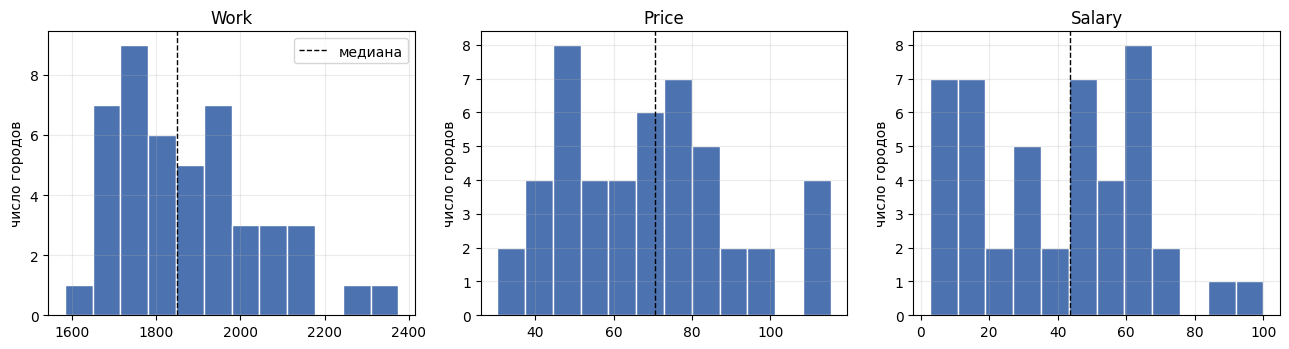

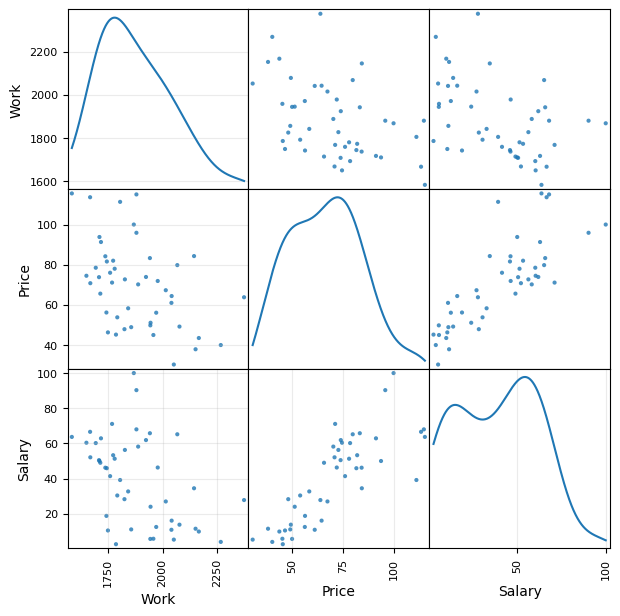

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


In [5]:
def plot_hists(X):
    # 12 интервалов: правило Фридмана–Диакониса даёт для Salary всего 4 и прячет две группы зарплат
    axes = plt.subplots(1, 3, figsize=(13, 3.6))[1]
    for ax, f in zip(axes, FEATURES):
        ax.hist(X[f].dropna(), bins=12, color='#4c72b0', edgecolor='white')
        ax.axvline(X[f].median(), color='black', ls='--', lw=1, label='медиана')
        ax.set(title=f, ylabel='число городов')
    axes[0].legend()
    plt.tight_layout()


plot_hists(X)
plt.show()

pd.plotting.scatter_matrix(X, figsize=(7, 7), diagonal='kde', alpha=0.8)
plt.show()
X.corr().round(2)

На гистограмме Salary в районе 35–43 столбик низкий, а у Work (за 2 200) и Salary (за 80) справа стоят отдельные столбики. Проверяю это по числам: сколько городов в каждом диапазоне зарплат и кто стоит на краях.

In [6]:
display(pd.cut(X.Salary, [0, 35, 40, 75, 100]).value_counts(sort=False).rename('городов').to_frame())
print('Salary между 35 и 40:', X.Salary[X.Salary.between(35, 40)].to_dict())
print('Самые высокие Salary:', X.Salary.nlargest(4).to_dict())
print('Самые длинные рабочие годы:', X.Work.nlargest(4).to_dict())

,городов
Salary,
"(0, 35]",21
"(35, 40]",1
"(40, 75]",22
"(75, 100]",2


Salary между 35 и 40: {'Stockholm': 39.2}
Самые высокие Salary: {'Zurich': 100.0, 'Geneva': 90.3, 'Luxembourg': 71.1, 'Tokyo': 68.0}
Самые длинные рабочие годы: {'Hong_Kong': 2375.0, 'Manila': 2268.0, 'Kuala_Lumpur': 2167.0, 'Bogota': 2152.0}


Что я вижу:

* Признаки в совсем разных шкалах: Work в среднем около 1 880 часов со стандартным отклонением ~174, а Price и Salary в среднем 69 и 40 со стандартным отклонением 22 и 25.
* Price и Salary сильно связаны (корреляция 0.80): где дорого, там и платят больше. С Work оба связаны отрицательно (−0.45 и −0.46): в богатых городах работают меньше часов.
* Зарплаты примерно делятся на две группы: 21 город с Salary до 35 и 24 города от 40, между ними только Stockholm (39.2). Zurich (100) и Geneva (90.3) заметно выше всех остальных: следующий Luxembourg с 71.1.
* У Work длинный правый хвост: больше 2 200 часов работают только Hong_Kong (2 375) и Manila (2 268), следующий Kuala_Lumpur с 2 167.

Беру все три признака: их немного, и каждый описывает свою сторону жизни в городе: сколько работают, сколько всё стоит и сколько платят. Но из-за корреляции Price и Salary направление «дорого и богато» в расстояниях учитывается почти дважды.

## 3. Подготовка данных

У Cairo и Jakarta нет рабочих часов и зарплаты. Удалять города не хочется: тогда они не попадут ни в один кластер. Поэтому заполняю пропуски медианой: она не чувствительна к выбросам вроде Zurich. При этом понимаю, что положение этих двух городов фактически определяется одной ценой, так что их принадлежность к кластеру условна.

Разные шкалы признаков сразу ставят вопрос: нужно ли стандартизовать? Кластеризация опирается на расстояния между городами, и признак с большим разбросом в них перевесит остальные. Насколько сильно, показывает доля каждого признака в общей дисперсии (дисперсия это средний квадрат отклонения от среднего, мера разброса).

In [7]:
filled = SimpleImputer(strategy='median').fit_transform(X)
print('Доля каждого признака в общей дисперсии без масштабирования, %:')
print(pd.Series(filled.var(axis=0) / filled.var(axis=0).sum() * 100, index=FEATURES).round(1))

Доля каждого признака в общей дисперсии без масштабирования, %:
Work      96.5
Price      1.6
Salary     1.9
dtype: float64


На Work приходится 96.5 % всей дисперсии. Без масштабирования расстояния между городами почти целиком определялись бы часами работы, а цены и зарплаты почти ни на что не влияли бы. Значит, стандартизую сразу.

Беру z-оценки: z = (значение − среднее) / стандартное отклонение. После этого у каждого признака среднее 0 и стандартное отклонение 1, а значение показывает, на сколько стандартных отклонений город выше или ниже среднего. Исходную таблицу `X` оставляю как есть, стандартизованные значения храню отдельно в `Z`.

In [8]:
def prepare(X):
    # пропуски -> медиана признака, затем z-оценки (среднее 0, стандартное отклонение 1)
    return StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X))


Z = prepare(X)
zdf = pd.DataFrame(Z, index=X.index, columns=FEATURES)
display(pd.DataFrame({'среднее': zdf.mean(), 'стандартное отклонение': zdf.std(ddof=0)}).T.round(2))  # ddof=0, как в StandardScaler
zdf.loc[['Zurich', 'Geneva', 'Paris', 'Manila', 'Hong_Kong']].round(2)

,Work,Price,Salary
среднее,0.0,0.0,-0.0
стандартное отклонение,1.0,1.0,1.0


,Work,Price,Salary
City,,,
Zurich,-0.06,1.44,2.51
Geneva,0.01,1.25,2.11
Paris,-0.80,0.59,0.26
Manila,2.31,-1.34,-1.49
Hong_Kong,2.94,-0.23,-0.50


Теперь все три признака в одной шкале. Например, у Zurich Salary = 2.51: зарплата на два с половиной стандартных отклонения выше средней. У Hong_Kong Work = 2.94: почти три стандартных отклонения по часам работы.

## 4. Расстояния и метод связи

Похожесть городов измеряю евклидовым расстоянием в z-оценках: корень из суммы квадратов разностей по трём признакам. Посмотрю на нескольких городах, какие получаются числа.

In [9]:
from scipy.spatial.distance import pdist, squareform

dist = pd.DataFrame(squareform(pdist(Z)), index=X.index, columns=X.index)
dist.loc[['Zurich', 'Paris', 'Manila'], ['Geneva', 'Paris', 'Manila', 'Bombay']].round(2)

City,Geneva,Paris,Manila,Bombay
City,,,,
Zurich,0.45,2.52,5.42,5.22
Paris,2.12,0.00,4.05,3.44
Manila,4.99,4.05,0.00,1.36


Zurich и Geneva почти соседи (0.45), Zurich и Paris уже дальше (2.52), а Zurich и Manila на разных краях (5.42). Manila ближе всего к Bombay (1.36). Кластеризация собирает в группы как раз такие близкие города.

Иерархическая агломеративная кластеризация работает так. Сначала каждый город сам по себе кластер, их 48. На каждом шаге два самых близких кластера объединяются в один, и так до тех пор, пока все города не окажутся в одном кластере. Получается 47 слияний, из них строится дерево.

Пока кластер состоит из одного города, расстояние между кластерами равно расстоянию между городами. Когда в кластере несколько городов, нужно правило, как измерять расстояние между двумя группами. Это правило называется методом связи:

* single (ближний сосед): расстояние между группами равно расстоянию между двумя их самыми близкими городами. Достаточно одной пары близких городов, чтобы группы слились, поэтому получаются длинные цепочки;
* complete (дальний сосед): расстояние по двум самым далёким городам. Группы сливаются, только если все их города близки;
* average: среднее всех попарных расстояний между городами двух групп;
* ward: объединяет ту пару групп, при которой меньше всего растёт сумма квадратов расстояний от городов до центров их групп. Поэтому группы получаются компактными и похожего размера. Работает только с евклидовым расстоянием.

Строю дерево каждым методом. Чтобы получить k групп, дерево режу так, чтобы осталось k кластеров: при k = 2 это два последних больших куска, при k = 3 три и так далее. Сравниваю, на какие по размеру группы делят города разные методы.

In [10]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette

LINKAGES = ['ward', 'average', 'complete', 'single']


def cut(tree, k):
    # режу готовое дерево так, чтобы получилось k кластеров
    return fcluster(tree, t=k, criterion='maxclust')


def hierarchical_labels(Z, k, method='ward'):
    return cut(linkage(Z, method=method), k)


def sizes(labels):
    # размеры кластеров по убыванию, например '25 / 23'
    return ' / '.join(map(str, sorted(np.bincount(labels)[1:], reverse=True)))


trees = {m: linkage(Z, method=m) for m in LINKAGES}  # дерево строится один раз, потом режется на разные k
pd.DataFrame({m: [sizes(cut(tree, k)) for k in range(2, 7)] for m, tree in trees.items()},
             index=pd.Index(range(2, 7), name='k'))

,ward,average,complete,single
k,,,,
2,25 / 23,25 / 23,25 / 23,47 / 1
3,25 / 14 / 9,25 / 21 / 2,25 / 13 / 10,46 / 1 / 1
4,19 / 14 / 9 / 6,21 / 19 / 6 / 2,19 / 13 / 10 / 6,44 / 2 / 1 / 1
5,14 / 14 / 9 / 6 / 5,21 / 19 / 4 / 2 / 2,19 / 13 / 6 / 5 / 5,43 / 2 / 1 / 1 / 1
6,14 / 12 / 9 / 6 / 5 / 2,19 / 12 / 9 / 4 / 2 / 2,19 / 13 / 5 / 5 / 4 / 2,41 / 2 / 2 / 1 / 1 / 1


В каждой клетке размеры групп. Ward, average и complete при k = 2 делят города на 25 и 23. Single ведёт себя совсем иначе: при k = 2 он отрезает один город (47 / 1), при k = 3 ещё один (46 / 1 / 1), и основная масса остаётся одним куском. Это эффект цепочки: через цепочку близких соседей все обычные города связаны, а отделяются только одиночки на краях. Average с k = 3 тоже начинает отщеплять маленькие группы по два города. У Ward группы остаются крупными, их можно описать словами.

Одинаковые размеры ещё не значат одинаковый состав. Совпадают ли сами группы при k = 2? Для этого есть ARI (adjusted Rand index). Он перебирает все пары городов и смотрит, согласны ли два разбиения: оба ли кладут пару в одну группу или оба в разные. ARI = 1 значит, что разбиения совпадают полностью, около 0 значит согласие на уровне случайного. Номера кластеров на ARI не влияют, важен только состав.

In [11]:
ward2 = cut(trees['ward'], 2)
pd.Series({m: adjusted_rand_score(ward2, cut(trees[m], 2)) for m in LINKAGES[1:]}, name='ARI с Ward при k = 2').round(3).to_frame()

,ARI с Ward при k = 2
average,1.000
complete,1.000
single,0.004


Average и complete при k = 2 дают в точности то же разбиение, что Ward (ARI = 1). У single ARI почти 0: разбиение «47 и 1» с ними ничего общего не имеет. Мне нужны компактные группы похожих городов, поэтому основным методом беру Ward с евклидовым расстоянием.

Одноточечный кластер у single я считаю кандидатом в выбросы. Смотрю, кого single отрезает и насколько эти города далеки от остальных.

In [12]:
from sklearn.neighbors import NearestNeighbors

for k in (2, 3, 4):
    single = cut(trees['single'], k)
    print(f'single, k = {k}, кластеры из 1–2 городов:',
          [X.index[single == g].tolist() for g in np.unique(single) if (single == g).sum() <= 2])

nn_dist, nn_idx = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z)  # столбец 0 это сам город
print('Медиана расстояния до ближайшего соседа:', round(np.median(nn_dist[:, 1]), 2))
X.join(zdf.round(2).add_prefix('z_')).assign(**{'ближайший сосед': X.index[nn_idx[:, 1]],
                                                'до ближайшего соседа': nn_dist[:, 1].round(2)}).nlargest(5, 'до ближайшего соседа')

single, k = 2, кластеры из 1–2 городов: [['Hong_Kong']]
single, k = 3, кластеры из 1–2 городов: [['Tokyo'], ['Hong_Kong']]
single, k = 4, кластеры из 1–2 городов: [['Geneva', 'Zurich'], ['Tokyo'], ['Hong_Kong']]
Медиана расстояния до ближайшего соседа: 0.39


,Work,Price,Salary,z_Work,z_Price,z_Salary,ближайший сосед,до ближайшего соседа
City,,,,,,,,
Hong_Kong,2375.0,63.8,27.8,2.94,-0.23,-0.50,Manila,1.61
Tokyo,1880.0,115.0,68.0,0.01,2.14,1.18,Helsinki,1.26
Taipei,2145.0,84.3,34.5,1.58,0.72,-0.22,Tel_Aviv,1.15
Stockholm,1805.0,111.3,39.2,-0.44,1.97,-0.02,Madrid,1.09
Los_Angeles,2068.0,79.8,65.2,1.12,0.51,1.06,New_York,0.76


Single при k = 2 отрезает **Hong_Kong**. У него самый длинный рабочий год в наборе (2 375 часов, z = 2.94), а цены и зарплата средние. Ближайший к нему город, Manila, находится на расстоянии 1.61, тогда как у типичного города ближайший сосед в 0.39. Это кандидат в выбросы. Ошибкой данных он не выглядит: в таком значении нет ничего невозможного, город просто сильно отличается от остальных по одному признаку. Дальше single по одному отрезает Tokyo (цены 115.0, почти максимум набора 115.5) и пару Geneva и Zurich (самые высокие зарплаты).

Нужно ли удалять Hong_Kong? Смотрю, с кем он оказывается у Ward при разном числе кластеров.

In [13]:
hk = X.index.get_loc('Hong_Kong')
hk_groups = {k: cut(trees['ward'], k) for k in range(2, 9)}
pd.DataFrame({k: {'размер группы Hong_Kong': int((lab == lab[hk]).sum()),
                  'с кем (если группа меньше 5)': ', '.join(X.index[lab == lab[hk]]) if (lab == lab[hk]).sum() < 5 else ''}
              for k, lab in hk_groups.items()}).rename_axis('k', axis=1)

k,2,3,4,5,6,7,8
размер группы Hong_Kong,23,14,14,14,2,2,2
с кем (если группа меньше 5),,,,,"Hong_Kong, Taipei","Hong_Kong, Taipei","Hong_Kong, Taipei"


У Ward Hong_Kong ни при каком k от 2 до 8 не остаётся один: при k = 2 он в группе из 23 городов, при k = 3–5 из 14, при k = 6–8 в паре с Taipei. Ward не делает из него отдельный кластер, поэтому оставляю Hong_Kong в данных.

## 5. Дендрограмма и число кластеров

Дендрограмма рисует всё дерево слияний Ward. Внизу листья, это города. Каждая горизонтальная перекладина означает слияние двух кластеров, а её высота показывает, насколько непохожие группы пришлось объединить: у Ward высота растёт вместе с тем, насколько увеличивается разброс внутри объединённой группы. Если провести горизонтальную линию на какой-то высоте, число пересечённых вертикальных линий и будет числом кластеров.

Высоты последних 6 слияний: [12.46  5.55  4.8   3.73  3.42  3.04]


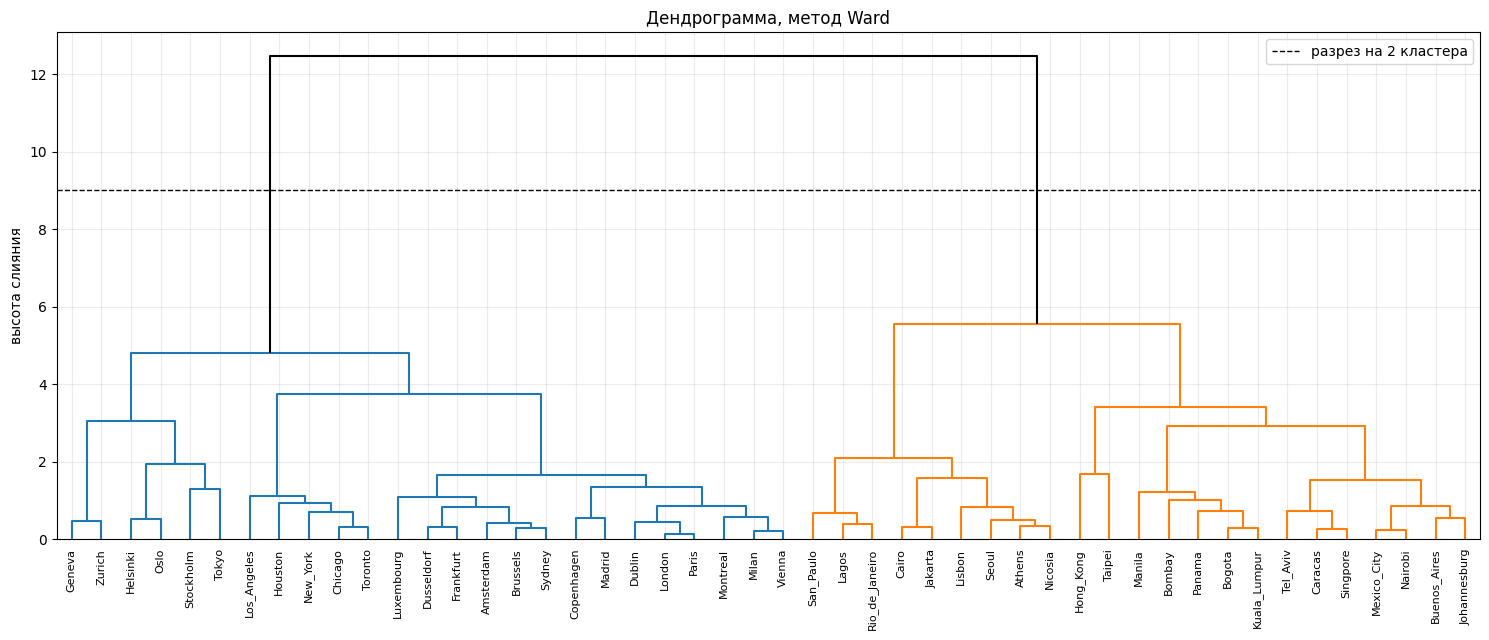

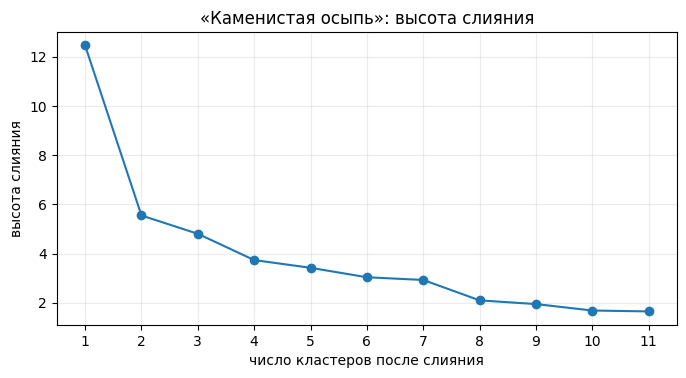

In [14]:
Lw = trees['ward']
heights = Lw[::-1, 2]  # высоты слияний, от последнего к первому
print('Высоты последних 6 слияний:', heights[:6].round(2))

fig, ax = plt.subplots(figsize=(15, 6.5))
threshold = (heights[0] + heights[1]) / 2  # порог посередине между двумя последними слияниями
set_link_color_palette([COLORS[1], COLORS[2]])
dendrogram(Lw, labels=X.index.tolist(), leaf_rotation=90, leaf_font_size=8, color_threshold=threshold,
           above_threshold_color='black', ax=ax)
ax.axhline(threshold, color='black', ls='--', lw=1, label='разрез на 2 кластера')
ax.set(title='Дендрограмма, метод Ward', ylabel='высота слияния')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(1, 12), heights[:11], 'o-')
ax.set(title='«Каменистая осыпь»: высота слияния', xlabel='число кластеров после слияния', ylabel='высота слияния',
       xticks=range(1, 12))
plt.show()

Как я читаю дендрограмму. Самое последнее слияние, двух больших ветвей, происходит на высоте 12.46. Все предыдущие слияния не выше 5.55. Значит, между 5.55 и 12.46 есть большой пустой промежуток: если резать дерево на любой высоте внутри него, получается одно и то же, два кластера. Чем длиннее такой промежуток, тем лучше группы отделены друг от друга и тем меньше решение зависит от точного места разреза. Для трёх кластеров промежуток между 4.80 и 5.55 гораздо короче.

«Каменистая осыпь» показывает те же высоты слияний по порядку. Ищу излом: место, после которого кривая идёт полого. Переход от двух кластеров к одному стоит 12.46, а дальше высоты убывают плавно (5.55, 4.80, 3.73, 3.42, ...). Излом при k = 2, после него выраженных скачков нет.

Посмотрю глазами, как делятся города при разном k. Трёхмерные z-оценки на плоском рисунке не показать, поэтому использую главные компоненты (PCA): это поворот осей, при котором первая ось идёт вдоль направления самого большого разброса городов, вторая вдоль следующего. Если две компоненты сохраняют почти весь разброс, плоская картинка почти не искажает расстояния. На кластеризацию PCA не влияет, она только для рисунка.

Доля разброса, которую сохраняют две компоненты: [0.704 0.217] → 0.921


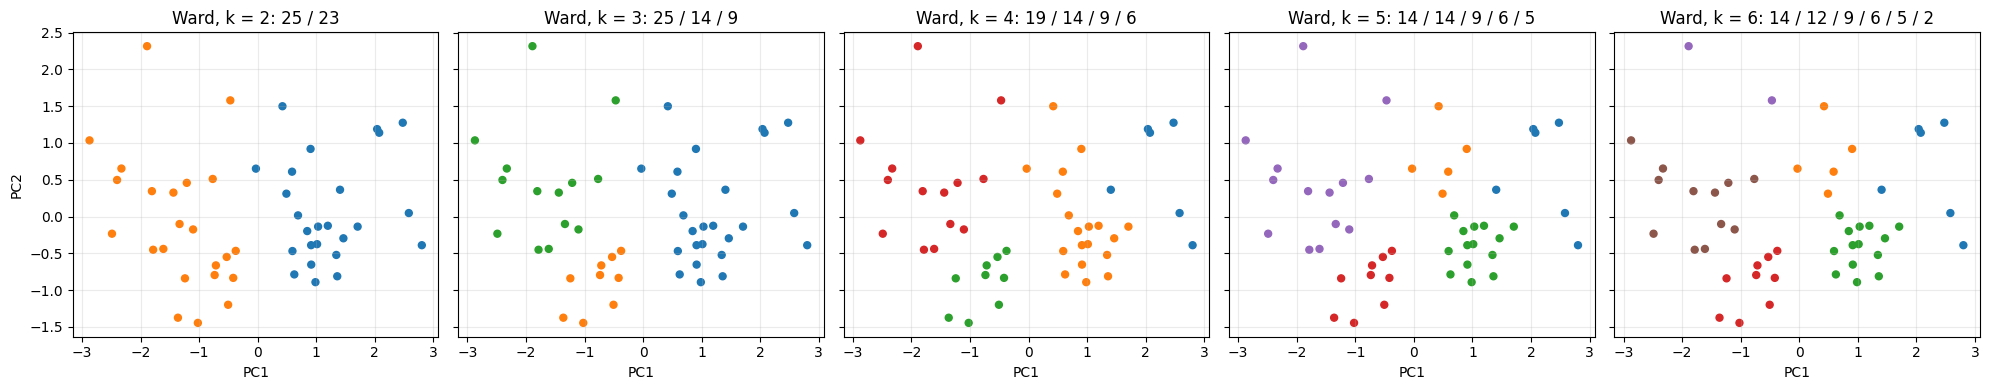

In [15]:
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
print('Доля разброса, которую сохраняют две компоненты:', pca.explained_variance_ratio_.round(3), '→',
      round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, k in zip(axes, range(2, 7)):
    lab = cut(Lw, k)
    ax.scatter(P[:, 0], P[:, 1], c=[f'C{g - 1}' for g in lab], s=25)
    ax.set(title=f'Ward, k = {k}: {sizes(lab)}', xlabel='PC1')
axes[0].set_ylabel('PC2')
plt.tight_layout()
plt.show()

Две главные компоненты сохраняют 92 % разброса. При k = 2 города делятся на левую и правую половины облака, граница проходит по первой компоненте. При k = 3 одна из половин делится ещё на две части. При k = 4–6 от групп отщепляются всё более мелкие куски, и границы между ними на рисунке размыты. Глазами два кластера выглядят самым естественным делением.

Кроме дендрограммы есть формальные метрики качества разбиения. Каждая сводит разбиение к одному числу, поэтому считаю их для k от 2 до 8 и смотрю, при каком k каждая лучше:

* silhouette. Для каждого города считаю a, среднее расстояние до городов своего кластера, и b, среднее расстояние до городов ближайшего чужого кластера. Силуэт города s = (b − a) / max(a, b): близко к 1, если город глубоко внутри своей группы, около 0, если он на границе, и меньше 0, если он ближе к чужой группе. Силуэт разбиения равен среднему по всем городам. Больше лучше;
* индекс Calinski-Harabasz (CH): отношение разброса между центрами кластеров к разбросу внутри кластеров, с поправкой на число кластеров и городов. Больше лучше: группы далеко друг от друга и плотные внутри;
* индекс Davies-Bouldin (DB): для каждого кластера находит самого похожего соседа и считает отношение «сумма разбросов двух кластеров / расстояние между их центрами», потом усредняет по кластерам. Меньше лучше.

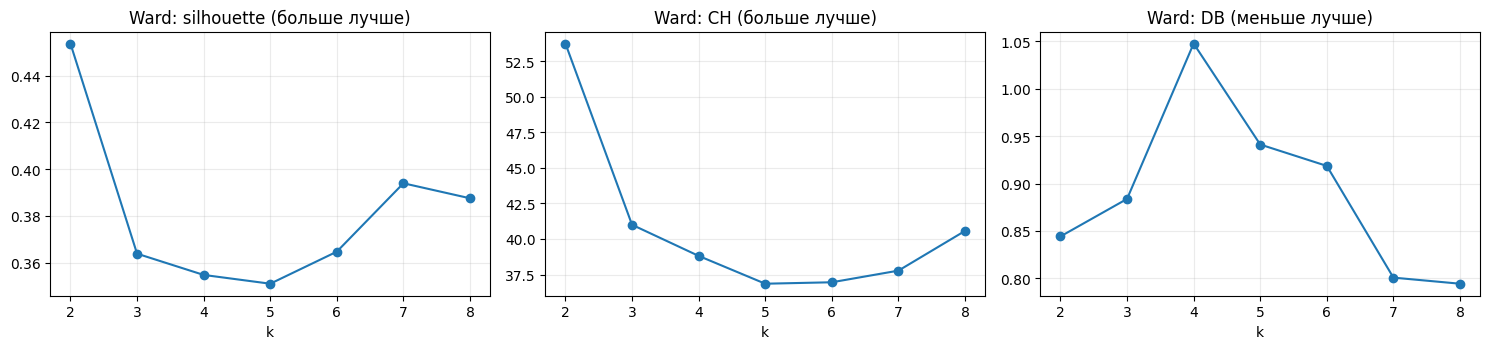

,silhouette,CH,DB,min_size
k,,,,
2,0.454,53.742,0.844,23
3,0.364,40.997,0.884,9
4,0.355,38.809,1.048,6
5,0.351,36.852,0.941,5
6,0.365,36.954,0.919,2
7,0.394,37.773,0.801,2
8,0.388,40.566,0.794,2


In [16]:
def quality(Z, labels):
    return {'silhouette': silhouette_score(Z, labels),
            'CH': calinski_harabasz_score(Z, labels),
            'DB': davies_bouldin_score(Z, labels)}


rows = []
for method, tree in trees.items():
    for k in range(2, 9):
        lab = cut(tree, k)
        rows.append({'method': method, 'k': k, **quality(Z, lab), 'min_size': np.bincount(lab)[1:].min()})
grid = pd.DataFrame(rows)
ward_grid = grid[grid.method == 'ward'].set_index('k').drop(columns='method')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, better in zip(axes, ['silhouette', 'CH', 'DB'], ['больше', 'больше', 'меньше']):
    ax.plot(ward_grid.index, ward_grid[col], 'o-')
    ax.set(title=f'Ward: {col} ({better} лучше)', xlabel='k')
plt.tight_layout()
plt.show()
ward_grid.round(3)

В таблице метрики Ward для k от 2 до 8, `min_size` это размер самого маленького кластера:

* silhouette максимален при k = 2, 0.454, при k = 3 падает до 0.364;
* CH тоже максимален при k = 2 (53.7);
* DB немного лучше при k = 7–8 (0.801 и 0.794 против 0.844 при k = 2), но там появляются группы из двух городов, а на 48 городах такие группы мало что говорят.

Главным аргументом силуэт я не делаю. Он часто даёт максимум как раз при двух кластерах, плохо оценивает вытянутые кластеры и отвечает только на вопрос «насколько кластеры круглые и разделённые». Сколько групп имеет смысл выделять, из него не следует. Здесь силуэт и CH просто не спорят с дендрограммой.

Основное решение k = 2.

In [17]:
def relabel_by_salary(labels, X):
    # нумерую кластеры по убыванию медианной зарплаты: кластер 1 самый высокооплачиваемый
    labels = np.asarray(labels)
    groups = sorted(set(labels), key=lambda g: -X.Salary[labels == g].median())
    new = {g: i + 1 for i, g in enumerate(groups)}
    return np.array([new[g] for g in labels])


K = 2
labels = relabel_by_salary(cut(Lw, K), X)
scores = quality(Z, labels)
for g in sorted(set(labels)):
    print(f'Кластер {g}, городов: {(labels == g).sum()}.', ', '.join(X.index[labels == g]))

Кластер 1, городов: 25. Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2, городов: 23. Athens, Bogota, Bombay, Buenos_Aires, Cairo, Caracas, Hong_Kong, Jakarta, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Taipei, Tel_Aviv


## 6. Чем отличаются кластеры

Номера кластеров расставляю по убыванию медианной зарплаты: кластер 1 более высокооплачиваемый. Для каждого кластера считаю средние и медианы по каждому признаку в исходных единицах. Заполненные Work и Salary у Cairo и Jakarta в расчёт не беру, только реальные значения.

,городов,Work среднее,Price среднее,Salary среднее,Work медиана,Price медиана,Salary медиана
кластер,,,,,,,
1,25,1789.2,85.0,59.0,1768.0,79.8,58.2
2,23,1987.9,51.3,16.3,1971.0,49.2,12.5


,Work,Price,Salary
1,-0.53,0.75,0.81
2,0.65,-0.81,-0.97


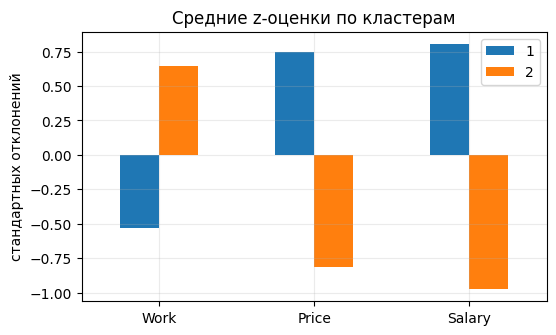

In [18]:
def profile(X, labels):
    # размер, средние и медианы по кластерам в исходных единицах; пропуски (NaN) в расчёт не попадают
    g = X.groupby(labels)
    return pd.concat([g.size().rename('городов'), g.mean().add_suffix(' среднее'),
                      g.median().add_suffix(' медиана')], axis=1).rename_axis('кластер')


display(profile(X, labels).round(1))

zmeans = zdf.where(X.notna()).groupby(labels).mean()
display(zmeans.round(2))
zmeans.T.plot.bar(color=[COLORS[g] for g in zmeans.index], rot=0, figsize=(6, 3.5),
                  title='Средние z-оценки по кластерам', ylabel='стандартных отклонений')
plt.show()

Таблица средних даёт первую картину. Средняя зарплата в кластере 1 равна 59 (59 % от цюрихской), в кластере 2 равна 16. Цены 85 против 51. Рабочих часов 1 789 против 1 988.

Вторая таблица и столбики показывают те же средние в z-оценках, то есть в стандартных отклонениях от среднего по всем городам. Кластер 1 выше среднего по ценам и зарплатам (+0.75 и +0.81) и ниже по часам работы (−0.53), кластер 2 наоборот. Сильнее всего группы расходятся по зарплатам.

Средние не показывают, насколько группы перекрываются. Для этого рисую ящики с усами. Ящик охватывает середину кластера: от 25-го до 75-го процентиля, то есть половину городов. Линия внутри ящика это медиана. Усы тянутся до самых дальних городов, которые отстоят от ящика не больше чем на полторы его высоты. Точки за усами подозрительны на выбросы. Если ящики двух кластеров по признаку не перекрываются, этот признак хорошо их разделяет.

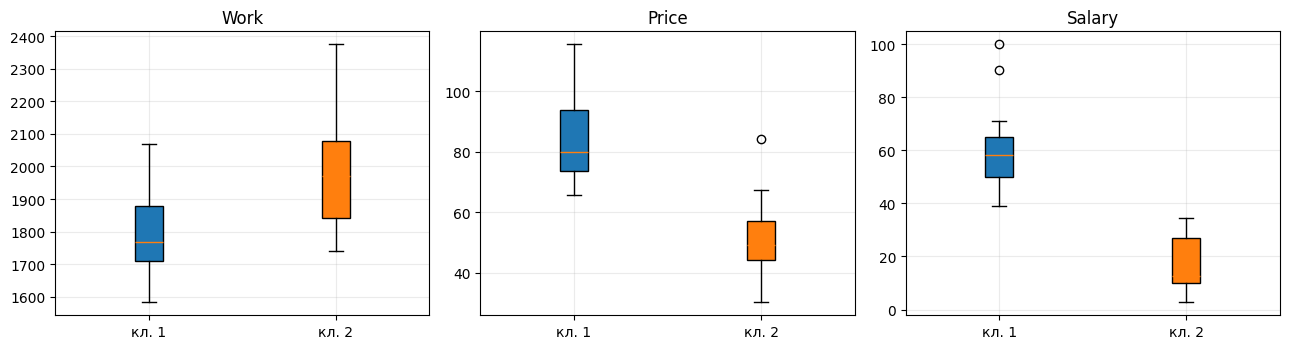

In [19]:
def plot_boxes(X, labels):
    # ящики с усами по кластерам; заполненные пропуски не рисую
    axes = plt.subplots(1, 3, figsize=(13, 3.6))[1]
    groups = sorted(set(labels))
    for ax, f in zip(axes, FEATURES):
        box = ax.boxplot([X.loc[labels == g, f].dropna() for g in groups], patch_artist=True)
        ax.set_xticks(range(1, len(groups) + 1), [f'кл. {g}' for g in groups])
        for patch, g in zip(box['boxes'], groups):
            patch.set_facecolor(f'C{g - 1}')
        ax.set(title=f)
    plt.tight_layout()


plot_boxes(X, labels)
plt.show()

По Salary и Price ящики не перекрываются: середина первого кластера целиком выше середины второго. По Salary не перекрываются даже усы: самая низкая зарплата первого кластера (Stockholm, 39.2) выше самой высокой во втором (Taipei, 34.5). Точки над усами Salary в первом кластере это Zurich и Geneva, точка над усом Price во втором это Taipei (84.3). По Work ящики частично перекрываются: в первом кластере есть города с длинным рабочим годом, например Los_Angeles (2 068 часов), а во втором с коротким.

Смотрю на сами кластеры в трёх стандартизованных признаках и на проекции с подписями городов.

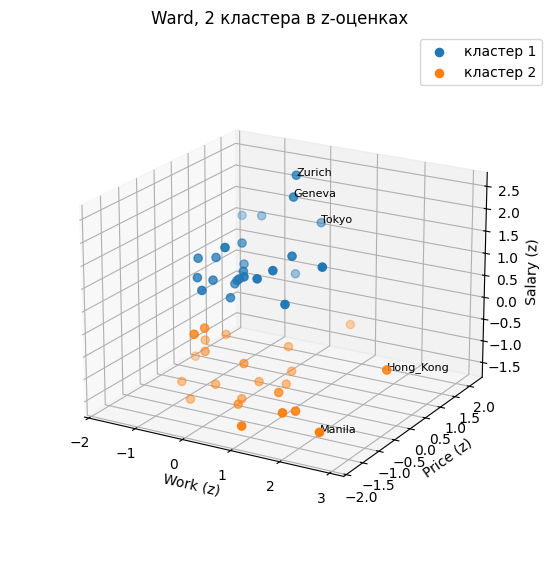

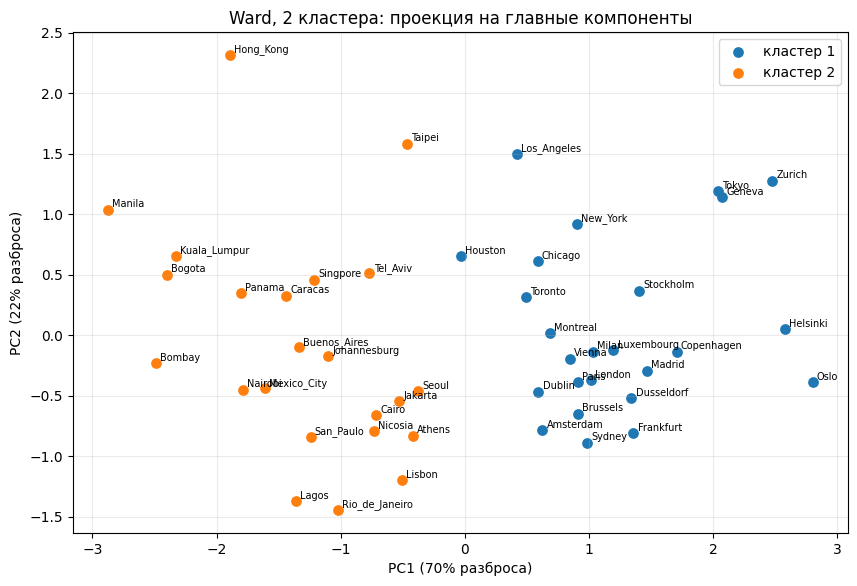

In [20]:
ax = plt.figure(figsize=(9, 7)).add_subplot(projection='3d')
for g in sorted(set(labels)):
    m = labels == g
    ax.scatter(Z[m, 0], Z[m, 1], Z[m, 2], c=COLORS[g], s=35, label=f'кластер {g}')
for city in ['Zurich', 'Geneva', 'Hong_Kong', 'Manila', 'Tokyo']:
    ax.text(*zdf.loc[city], city, fontsize=8)
ax.set(xlabel='Work (z)', ylabel='Price (z)', zlabel='Salary (z)', title='Ward, 2 кластера в z-оценках')
ax.view_init(elev=20, azim=-60)
ax.set_box_aspect(None, zoom=0.85)  # иначе подпись оси Salary обрезается
ax.legend()
plt.show()

ax = plt.subplots(figsize=(10, 6.5))[1]
for g in sorted(set(labels)):
    m = labels == g
    ax.scatter(P[m, 0], P[m, 1], s=45, c=COLORS[g], label=f'кластер {g}')
for (x, y), city in zip(P, X.index):
    ax.annotate(city, (x, y), fontsize=7, xytext=(3, 2), textcoords='offset points')
share = pca.explained_variance_ratio_
ax.set(xlabel=f'PC1 ({share[0]:.0%} разброса)', ylabel=f'PC2 ({share[1]:.0%} разброса)',
       title='Ward, 2 кластера: проекция на главные компоненты')
ax.legend()
plt.show()

В трёх измерениях кластеры лежат по разные стороны вдоль диагонали «высокие цены и зарплаты против долгой работы». На проекции с подписями видно, какие города где.

Получились два понятных типа городов.

**Кластер 1 (25 городов): дорогие города с высокими зарплатами и более коротким рабочим годом.** В среднем зарплата 59 % от цюрихской, цены 85 %, 1 789 рабочих часов. Сюда попали Западная и Северная Европа, США и Канада, Tokyo, Sydney: Paris, London, New_York, Toronto, Stockholm. Самые высокие значения у Zurich и Geneva (зарплата 90–100).

**Кластер 2 (23 города): дешевле, зарплаты в разы ниже, работают больше.** В среднем зарплата 16 %, цены 51 %, 1 988 часов. Это Латинская Америка, Азия, Африка, Ближний Восток и три города юга Европы: Bogota, Bombay, Manila, Nairobi, Athens, Lisbon, Nicosia. Madrid и Milan оказались в первом кластере.

Сильнее всего группы расходятся по зарплате (в 3.6 раза по средним) и ценам (в 1.7 раза). По часам работы разница около 200 часов в год, и диапазоны частично перекрываются. На проекции группы разделяются по первой компоненте, которая сохраняет 70 % разброса и задаёт ось «зарплаты и цены против часов работы». Cairo и Jakarta попали во второй кластер только по цене, так что для них это решение условное.

## 7. А если три кластера?

Два кластера для практики маловато. Что теряется, если оставить только два? Режу то же дерево на три и смотрю, какие группы получаются.

кластер при k = 3,1,2,3
кластер при k = 2,,,
1,25,0,0
2,0,9,14


,городов,Work среднее,Price среднее,Salary среднее,Work медиана,Price медиана,Salary медиана
кластер,,,,,,,
1,25,1789.2,85.0,59.0,1768.0,79.8,58.2
2,9,1798.9,48.6,19.2,1792.0,47.9,18.8
3,14,2082.4,53.1,14.9,2047.0,50.4,12.0


Кластер 2 при k = 3: Athens, Cairo, Jakarta, Lagos, Lisbon, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul
Кластер 3 при k = 3: Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, Johannesburg, Kuala_Lumpur, Manila, Mexico_City, Nairobi, Panama, Singpore, Taipei, Tel_Aviv


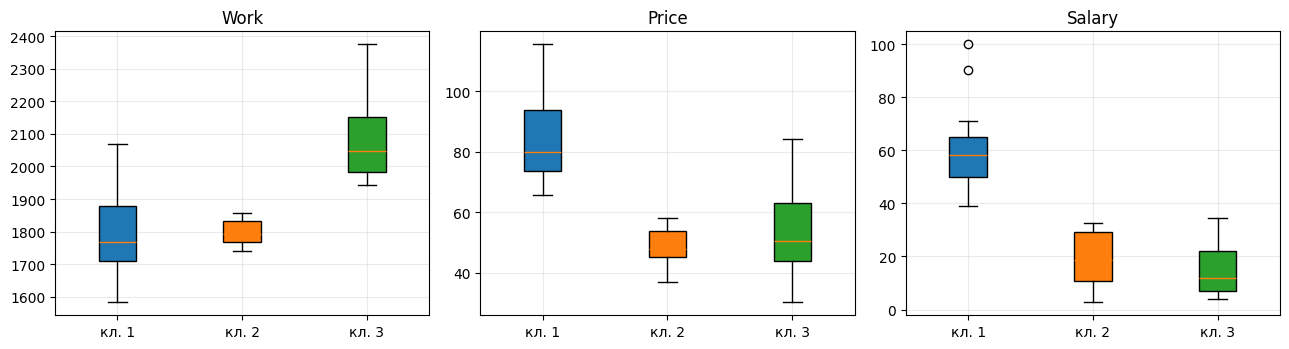

In [21]:
labels3 = relabel_by_salary(cut(Lw, 3), X)
display(pd.crosstab(pd.Series(labels, name='кластер при k = 2'), pd.Series(labels3, name='кластер при k = 3')))
display(profile(X, labels3).round(1))
for g in (2, 3):
    print(f'Кластер {g} при k = 3:', ', '.join(X.index[labels3 == g]))
plot_boxes(X, labels3)
plt.show()

Первая таблица показывает, откуда взялись три группы: строка это кластер при двух, столбец кластер при трёх, в клетке число общих городов. Все 25 городов первого кластера остались вместе, а второй кластер (23 города) разделился на 9 и 14.

* 9 городов (Athens, Lisbon, Nicosia, Seoul, Rio_de_Janeiro, San_Paulo, Lagos, Cairo, Jakarta) со средним рабочим годом 1 799 часов, почти как в первом кластере;
* 14 городов (Bombay, Manila, Hong_Kong, Taipei, Mexico_City, Bogota и др.) с самым длинным рабочим годом, в среднем 2 082 часа.

На ящиках с усами это хорошо видно: по Work новые кластеры 2 и 3 не перекрываются совсем, а по Price и Salary их ящики сильно перекрываются (цены в среднем 49 и 53, зарплаты 19 и 15). Значит, при объединении их в один кластер теряется только различие в часах работы среди небогатых городов.

Насколько устойчиво само деление на три? Проверяю его другим способом стандартизации: приведением каждого признака к отрезку [0, 1] (минимум становится 0, максимум 1). Если три группы реальные, они должны получиться и так.

In [22]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler().fit_transform(filled)  # каждый признак в [0, 1]
tree_mm = linkage(minmax, method='ward')
minmax3 = relabel_by_salary(cut(tree_mm, 3), X)
print('ARI с разбиением на z-оценках: k = 2:', round(adjusted_rand_score(labels, cut(tree_mm, 2)), 3),
      '| k = 3:', round(adjusted_rand_score(labels3, minmax3), 3))
display(pd.crosstab(pd.Series(labels3, name='z-оценки, k = 3'), pd.Series(minmax3, name='[0, 1], k = 3')))
X[minmax3 == 1].assign(**{'место по Price': X.Price.rank(ascending=False)[minmax3 == 1]})

ARI с разбиением на z-оценках: k = 2: 1.0 | k = 3: 0.55


"[0, 1], k = 3",1,2,3
"z-оценки, k = 3",,,
1,6,19,0
2,0,0,9
3,0,0,14


,Work,Price,Salary,место по Price
City,,,,
Geneva,1880.0,95.9,90.3,6.0
Helsinki,1667.0,113.6,66.6,3.0
Oslo,1583.0,115.5,63.7,1.0
Stockholm,1805.0,111.3,39.2,4.0
Tokyo,1880.0,115.0,68.0,2.0
Zurich,1868.0,100.0,100.0,5.0


При k = 2 приведение к [0, 1] даёт ровно те же два кластера (ARI = 1). При k = 3 решения расходятся (ARI 0.55): вместо деления второго кластера по часам работы отщепляются 6 самых дорогих городов набора, первые 6 мест по Price (Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich).

Оставляю k = 2 по трём причинам:

1. Третий кластер выделяется по одному признаку, Work, и на дендрограмме это слияние (5.55) не отделено скачком от следующих (4.80, 3.73).
2. Двое из девяти, Cairo и Jakarta, оказались в группе «с коротким рабочим годом» из-за Work, заполненного медианой (1 849 часов). Настоящих рабочих часов этих городов я не знаю.
3. Третья группа зависит от способа стандартизации, а два кластера нет.

Разбиение на три кластера я считаю возможной детализацией второго кластера: если задача требует отделить города с самым длинным рабочим годом, его можно использовать. Основной ответ: две группы.

## 8. Проверка устойчивости

Напоследок проверяю, не держится ли решение на отдельных моих выборах: на стандартизации, на заполнении пропусков и на том, что я оставил Hong_Kong. Каждый раз строю Ward заново и сравниваю с основным разбиением через ARI.

In [23]:
complete = X.notna().all(axis=1).to_numpy()
no_hk = (X.index != 'Hong_Kong')
labels_no_hk = relabel_by_salary(hierarchical_labels(prepare(X[no_hk]), K), X[no_hk])
display(pd.Series({
    'без масштабирования': adjusted_rand_score(labels, hierarchical_labels(filled, K)),
    'приведение к [0, 1]': adjusted_rand_score(labels, cut(tree_mm, K)),
    'без Cairo и Jakarta': adjusted_rand_score(labels[complete], hierarchical_labels(prepare(X[complete]), K)),
    'без Hong_Kong': adjusted_rand_score(labels[no_hk], labels_no_hk),
}, name='ARI с основным решением, k = 2').round(3).to_frame())
print('Без Hong_Kong сменили кластер:', X.index[no_hk][labels[no_hk] != labels_no_hk].tolist())

,"ARI с основным решением, k = 2"
без масштабирования,0.156
"приведение к [0, 1]",1.000
без Cairo и Jakarta,1.000
без Hong_Kong,0.915


Без Hong_Kong сменили кластер: ['Taipei']


* **Без масштабирования** разбиение получается совсем другим (ARI 0.16): алгоритм режет города почти только по часам работы. Стандартизация была нужна.
* **Приведение к [0, 1]** вместо z-оценок даёт те же два кластера (ARI = 1).
* **Без Cairo и Jakarta** остальные 46 городов делятся точно так же: заполнение пропусков на результат не повлияло.
* **Без Hong_Kong** меняет кластер один город, Taipei: он переходит в первый кластер (ARI 0.915). Taipei пограничный: цены у него высокие (84), зарплата средняя (34.5), рабочий год длинный. Остальные 46 городов остаются на месте, так что кандидат в выбросы решение не определяет.

## 9. Выводы

1. Пропуски у Cairo и Jakarta (`-9999`) заменил медианой. Признаки стандартизовал: без этого на Work приходилось бы 96.5 % дисперсии, и разбиение получилось бы другим (ARI 0.16). Z-оценки и приведение к [0, 1] при k = 2 дают одно и то же.
2. Метод Ward выделяет два кластера: 25 дорогих городов с высокими зарплатами и коротким рабочим годом (в среднем зарплата 59, цены 85, 1 789 часов) и 23 более дешёвых города с низкими зарплатами и длинным рабочим годом (16, 51, 1 988 часов).
3. Два кластера выбраны по скачку на дендрограмме и излому «каменистой осыпи» (12.46 против 5.55). Silhouette и CH тоже максимальны при k = 2, но это дополнительный аргумент.
4. При k = 3 второй кластер делится по часам работы, при этом цены и зарплаты частей почти одинаковы. Такое деление зависит от способа стандартизации, а два города попадают в него из-за заполненных пропусков, поэтому оставляю его как детализацию.
5. Single linkage отрезает Hong_Kong (самый длинный рабочий год) как кандидата в выбросы. Ward его не выделяет, а без него решение меняется только для пограничного Taipei.

Ограничения: всего 48 городов, данные 1991 года, у двух городов известна только цена, а Price и Salary сильно коррелируют.

In [24]:
def save_results(X, Z, P, labels, selection, summary):
    # сохраняю разбиение, подбор k и параметры с метриками в results/
    out = Path('results')
    out.mkdir(exist_ok=True)
    z = {f'z_{f}': Z[:, i] for i, f in enumerate(FEATURES)}
    X.assign(imputed=X.isna().any(axis=1), **z, PC1=P[:, 0], PC2=P[:, 1], cluster=labels).to_csv(out / 'assignments.csv')
    selection.to_csv(out / 'selection.csv', index=False)
    (out / 'summary.json').write_text(json.dumps({'n': len(X)} | summary, ensure_ascii=False, indent=2, default=float))


save_results(X, Z, P, labels, grid, {
    'params': {'linkage': 'ward', 'metric': 'euclidean', 'k': K},
    'rationale': 'скачок на дендрограмме и излом «каменистой осыпи» (12.46 против 5.55); silhouette и CH дополнительно тоже за k = 2',
    'clusters': K, 'noise': 0, 'metrics': scores, 'metrics_n': len(X),
    'merge_heights': heights[:10].tolist(),  # высоты последних слияний, от последнего
})